# Diffuse scattering and phonon populations

This notebook produces a **65 × 65 × 65** diffuse-scattering map for the bundled **5zck peptide crystal**, using the same structure as the repository's pump–probe notebook. It includes large, labeled log-scale slices, a model PDOS, an example frequency-dependent population enhancement, and the resulting intensity difference.

Use **Kernel → Restart Kernel and Run All Cells**. CPU is sufficient; no external data, GPU, or saved simulation is required. The small 13³ histidine smoke test remains available as [the command-line example](pytorch_diffuse.py). See [setup instructions](../docs/PYTORCH_QUICKSTART.md).

Files are written to `tmp/pytorch-notebook/` and replaced on rerun. The plots saved in this notebook are previews of the default run; rerun after changing inputs.

In [1]:
from pathlib import Path
import sys

# Jupyter may start the kernel in the repository root or in examples/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "eryx/models_torch.py").is_file()
             and (p / "tests/pdbs/histidine.pdb").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the eryx checkout")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic
from eryx.models_torch import OnePhonon
from matplotlib.colors import LogNorm, TwoSlopeNorm
import time
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

1 item had no tests:
    __main__
0 tests in 1 item.
0 passed.
Test passed.


## Inputs and plot controls

`SAMPLING` is (minimum, maximum, **samples per Miller-index unit**). `(-4, 4, 8)` gives 65 points per axis; use `(-4, 4, 16)` for 129³ when you want finer detail. Increasing the grid and replacing the peptide with a large protein both increase cost.

`SLICE_HKL` picks the nearest h, k, and l planes. Zero selects central planes. A fractional value such as 0.125 shows an off-Bragg plane. `PUMP_PERCENTILE`, `PUMP_WIDTH_FRACTION`, and `PUMP_GAIN` control the example population change below.

After editing this cell, run it and all following cells. Plot-only changes to `SLICE_HKL` or `COLOR_PERCENTILES` need the input cell and plotting cells rerun.

In [2]:
PDB = ROOT / "tests/pdbs/5zck_p1.pdb"
SAMPLING = (-4, 4, 8)
DEVICE = torch.device("cpu")
CPU_THREADS = 4
OUT = ROOT / "tmp/pytorch-notebook"
SLICE_HKL = (0.0, 0.0, 0.0)
COLOR_PERCENTILES = (2, 99.5)
PDOS_BINS = 80
PUMP_PERCENTILE = 30.0
PUMP_WIDTH_FRACTION = 0.08
PUMP_GAIN = 4.0
assert PDB.is_file(), f"Missing PDB: {PDB}"
assert 0 <= PUMP_PERCENTILE <= 100 and PUMP_WIDTH_FRACTION > 0 and PUMP_GAIN > 0
assert 0 <= COLOR_PERCENTILES[0] < COLOR_PERCENTILES[1] <= 100
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(CPU_THREADS)

## Build the model and calculate the baseline

The network is projected onto six rigid-body degrees of freedom per asymmetric unit. The baseline uses the model's default inverse-eigenvalue weights and PDB B-factors for displacement damping. Forward calculations run under `torch.no_grad()` to keep this visualization example's memory use low. This is not an optimization example; eigenvectors are also detached within the model.

In [3]:
started = time.perf_counter()
with torch.no_grad():
    model = OnePhonon(
        str(PDB), hsampling=SAMPLING, ksampling=SAMPLING, lsampling=SAMPLING,
        model="gnm", group_by="asu", expand_p1=True, res_limit=0.0,
        gnm_cutoff=4.0, gamma_intra=1.5, gamma_inter=0.7,
        device=DEVICE, n_processes=1,
    )
    intensity = model.apply_disorder(use_data_adp=True)
I = intensity.detach().cpu().numpy()
q = model.q_grid.detach().cpu().numpy()
hkl = model.hkl_grid.detach().cpu().numpy()
volume = I.reshape(model.map_shape)
valid = np.isfinite(I)
assert I.size == np.prod(model.map_shape) and valid.any() and I[valid].max() > 0
assert np.all(I[valid] >= 0)
hkl_volume = hkl.reshape(model.map_shape + (3,))
h_axis = hkl_volume[:, 0, 0, 0]
k_axis = hkl_volume[0, :, 0, 1]
l_axis = hkl_volume[0, 0, :, 2]
np.savez_compressed(
    OUT / "results.npz", intensity=I, q_vectors=q, hkl_grid=hkl,
    map_shape=model.map_shape, adp=model.ADP.detach().cpu().numpy(),
    covariance=model.covar.detach().cpu().numpy(),
)
print(f"{PDB.stem}: {model.map_shape}, {I.size:,} sampled points")
print(f"{valid.sum():,} finite intensities; baseline completed in {time.perf_counter()-started:.1f} s")

remove_ligands_and_waters(): missing entity_type in chain A


remove_ligands_and_waters(): missing entity_type in chain A


/home/ollie/Documents/eryx/eryx/models_torch.py:1284: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  r_cell = torch.tensor(r_cell_np, dtype=self.real_dtype, device=self.device)


5zck_p1: (65, 65, 65), 274,625 sampled points
273,896 finite intensities; baseline completed in 148.9 s


## Reciprocal-space slices

Each panel has Miller-index axes and uses the **same logarithmic color scale**, set from the displayed slices. Percentile clipping affects only display, not saved intensities. Gray pixels are missing data. No interpolation fills those gaps.

Miller coordinates are not Cartesian q coordinates; equal axis spacing here means equal reciprocal-index increments, not equal physical distances.

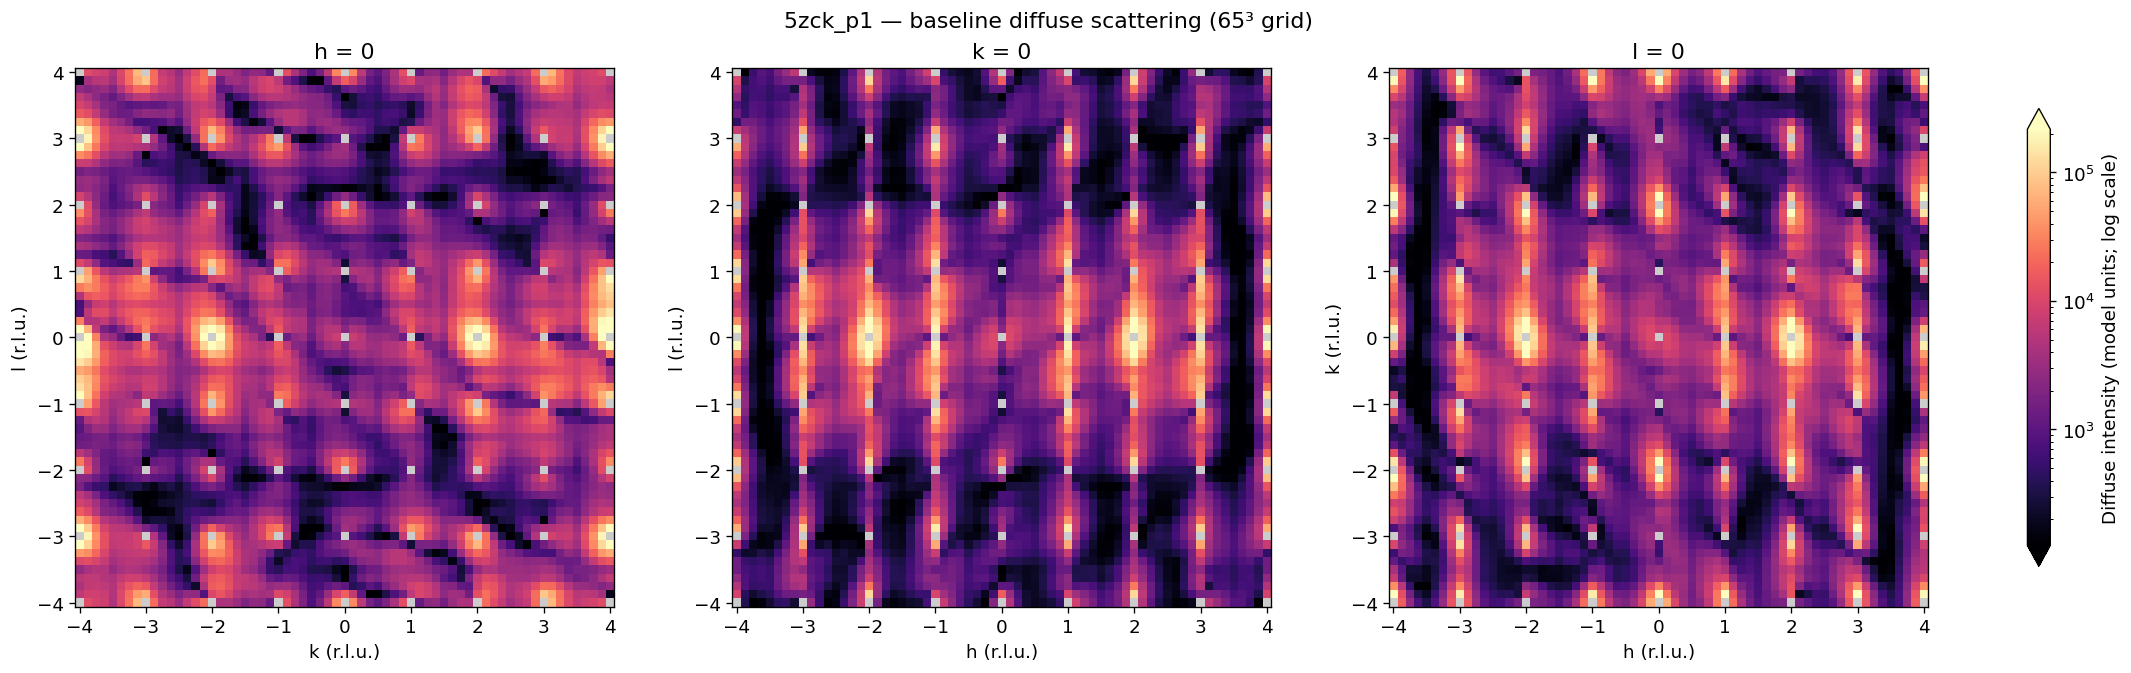

In [4]:
def draw_slice(ax, values, x, y, title, xlabel, ylabel, norm, cmap):
    mesh = ax.pcolormesh(x, y, np.ma.masked_invalid(values.T),
                         shading="nearest", cmap=cmap, norm=norm, rasterized=True)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, aspect="equal", facecolor="0.8")
    return mesh

hi, ki, li = [int(np.argmin(np.abs(axis-value)))
              for axis, value in zip((h_axis, k_axis, l_axis), SLICE_HKL)]
planes = [volume[hi, :, :], volume[:, ki, :], volume[:, :, li]]
positive = np.concatenate([p[np.isfinite(p) & (p > 0)] for p in planes])
assert positive.size > 0, "Choose slices with finite positive intensities"
vmin, vmax = np.percentile(positive, COLOR_PERCENTILES)
assert 0 < vmin < vmax, "Need nonconstant positive intensity for logarithmic contrast"
norm = LogNorm(vmin=vmin, vmax=vmax)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")
cmap = plt.get_cmap("magma").with_extremes(bad="0.8")
draw_slice(axes[0], planes[0], k_axis, l_axis, f"h = {h_axis[hi]:g}", "k (r.l.u.)", "l (r.l.u.)", norm, cmap)
draw_slice(axes[1], planes[1], h_axis, l_axis, f"k = {k_axis[ki]:g}", "h (r.l.u.)", "l (r.l.u.)", norm, cmap)
mesh = draw_slice(axes[2], planes[2], h_axis, k_axis, f"l = {l_axis[li]:g}", "h (r.l.u.)", "k (r.l.u.)", norm, cmap)
fig.colorbar(mesh, ax=axes, label="Diffuse intensity (model units; log scale)", shrink=0.85, extend="both")
fig.suptitle(f"{PDB.stem} — baseline diffuse scattering ({model.map_shape[0]}³ grid)")
fig.savefig(OUT / "slices.png", dpi=180)
plt.show()

## Example PDOS and frequency-selective populations

The left panel is the **unweighted model PDOS**: a histogram of mode frequencies. The right panel shows sums of the baseline and enhanced **scattering weights** in the same frequency bins. These are different quantities; a DOS histogram is not a population input that reproduces the baseline.

Following the existing pump–probe script's in-memory approach, multiply each baseline mode weight by a Gaussian enhancement centered at a chosen frequency percentile. `PUMP_GAIN=4` gives up to five times the baseline weight at the center. The frequencies, mode shapes, structure, and displacement damping stay fixed, isolating the effect of mode weights.

Frequency labels use the repository's **empirical THz scale**, not a measured calibration. This is an illustrative population perturbation, not a calibrated pump-energy or thermal-equilibrium model. See [PDOS interpretation](../docs/PDOS.md).

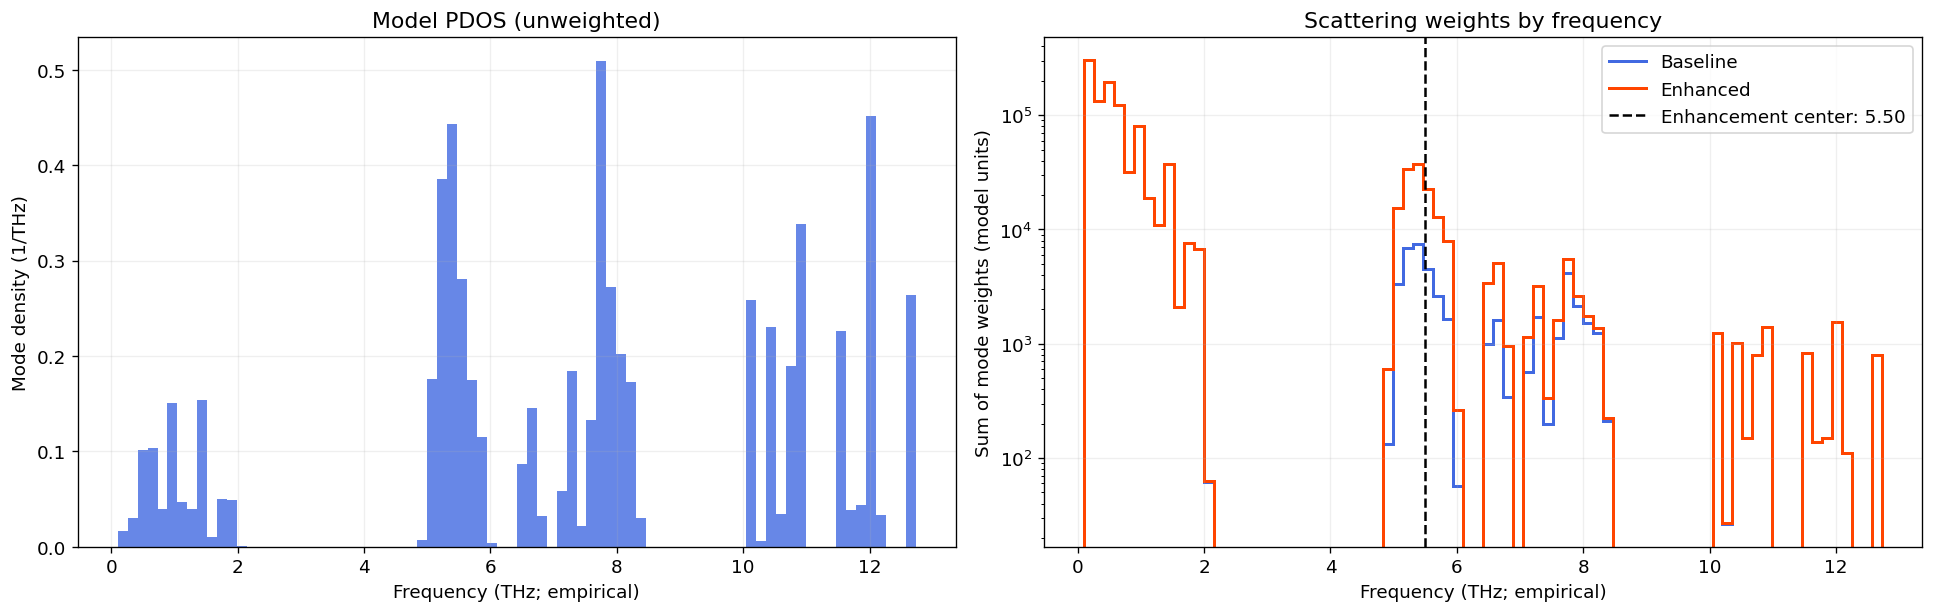

Enhancement center: 5.5; width: 1.01 (empirical THz)


In [5]:
baseline_weights = model.Winv.detach().clone()
# No input PDOS is used above, so the baseline Winv is 1/eigenvalue.
mode_frequency = (100 / (2 * np.pi)) * torch.sqrt(1 / baseline_weights.real)
mode_valid = torch.isfinite(mode_frequency) & (baseline_weights.real > 0)
frequencies = mode_frequency[mode_valid].cpu().numpy()
np.testing.assert_allclose(np.sort(frequencies), np.sort(model.get_frequencies_thz()), rtol=1e-10)
center = float(np.percentile(frequencies, PUMP_PERCENTILE))
width = PUMP_WIDTH_FRACTION * float(np.ptp(frequencies))
assert width > 0
boost = 1 + PUMP_GAIN * torch.exp(-0.5 * ((mode_frequency-center)/width)**2)
enhanced_weights = baseline_weights * boost
weight_before = baseline_weights.real[mode_valid].cpu().numpy()
weight_after = enhanced_weights.real[mode_valid].cpu().numpy()
assert np.all(weight_after >= weight_before)

pdos = model.generate_pdos(bins=PDOS_BINS)
np.savetxt(OUT / "pdos.dat", pdos, header="frequency_THz_empirical mode_density")
edges = np.histogram_bin_edges(frequencies, bins=PDOS_BINS)
counts_before, _ = np.histogram(frequencies, bins=edges, weights=weight_before)
counts_after, _ = np.histogram(frequencies, bins=edges, weights=weight_after)
np.savetxt(OUT / "population_histograms.dat",
           np.column_stack(((edges[:-1]+edges[1:])/2, counts_before, counts_after)),
           header="frequency_THz_empirical baseline_weight_sum enhanced_weight_sum")
# Two-column example accepted by pdos_mode='direct'; it is a weight curve, not DOS.
f_grid = np.linspace(frequencies.min(), frequencies.max(), 1000)
input_weight = (100 / (2*np.pi*f_grid))**2 * (1 + PUMP_GAIN*np.exp(-0.5*((f_grid-center)/width)**2))
np.savetxt(OUT / "example_population.dat", np.column_stack((f_grid, input_weight)),
           header="frequency_THz_empirical direct_population_weight")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
axes[0].hist(frequencies, bins=edges, density=True, color="royalblue", alpha=0.8)
axes[0].set(title="Model PDOS (unweighted)", xlabel="Frequency (THz; empirical)", ylabel="Mode density (1/THz)")
axes[1].stairs(counts_before, edges, label="Baseline", color="royalblue", linewidth=1.8)
axes[1].stairs(counts_after, edges, label="Enhanced", color="orangered", linewidth=1.8)
axes[1].axvline(center, color="black", linestyle="--", label=f"Enhancement center: {center:.2f}")
axes[1].set(title="Scattering weights by frequency", xlabel="Frequency (THz; empirical)", ylabel="Sum of mode weights (model units)")
axes[1].set_yscale("log")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(OUT / "pdos_populations.png", dpi=180)
plt.show()
print(f"Enhancement center: {center:.3g}; width: {width:.3g} (empirical THz)")

## Scattering response to the example population

Compute with the enhanced weights on the same model, then restore the baseline even if calculation fails. The first two panels share a log scale. The third shows **enhanced − baseline** on a symmetric linear scale centered at zero. Negative differences are not expected for this positive weight enhancement with fixed damping; a check below verifies that.

`example_population.dat` demonstrates the two-column format for `pdos_path` with `pdos_mode="direct"`. This calculation applies the analytic enhancement to modes directly; loading the sampled file instead introduces interpolation error. `pdos.dat` is the separate unweighted histogram.

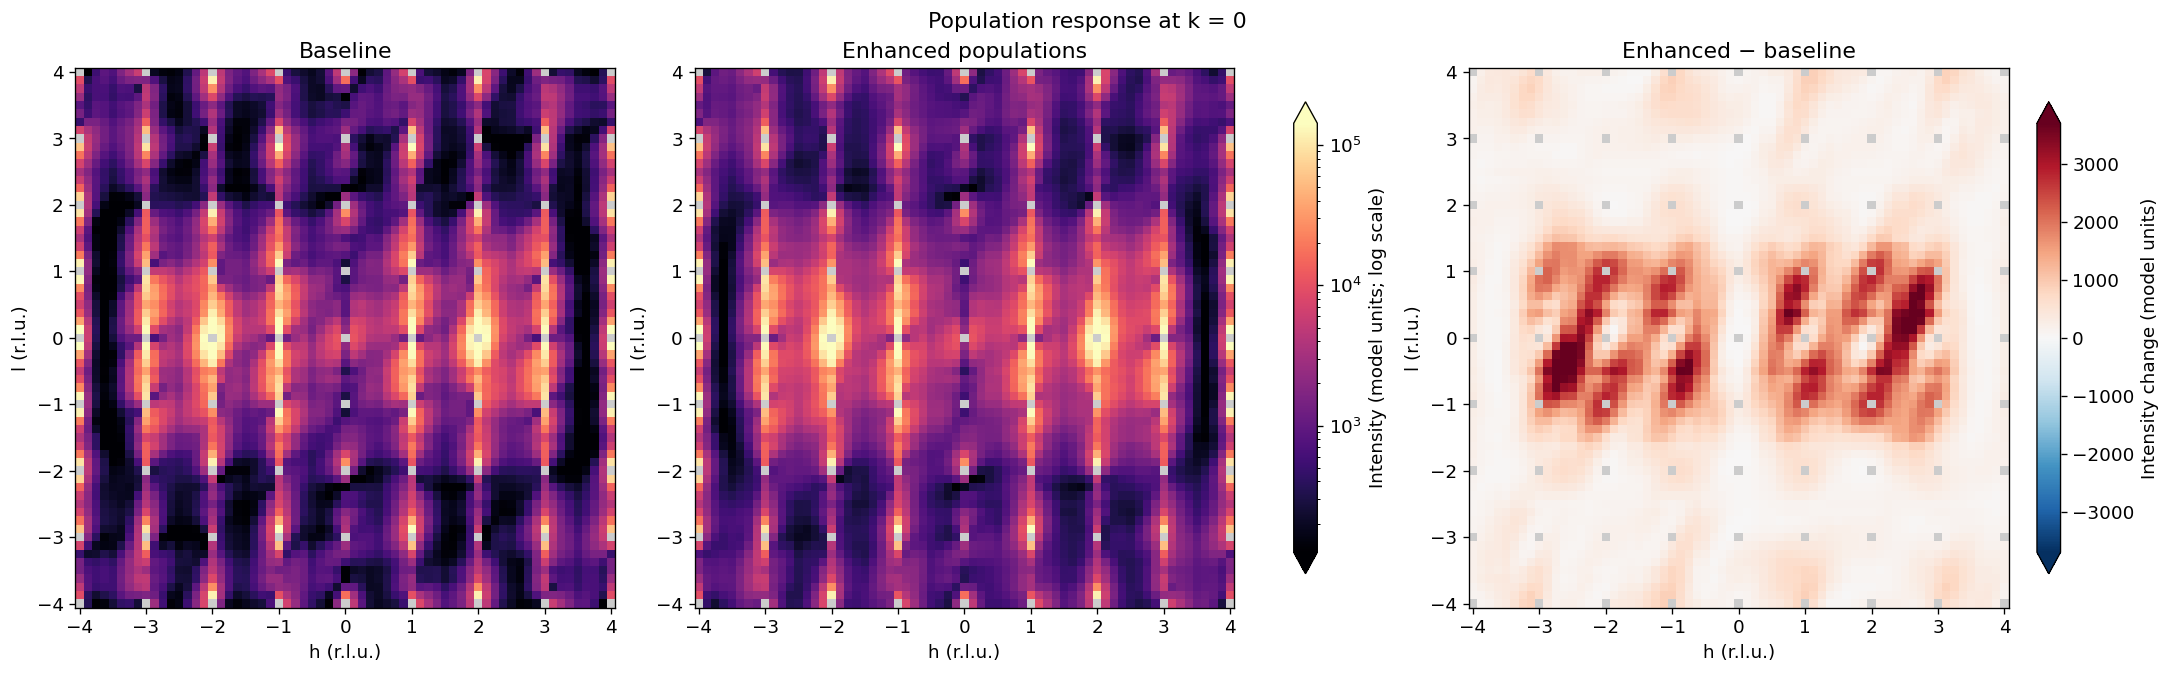

In [6]:
try:
    with torch.no_grad():
        model.Winv = enhanced_weights
        enhanced_intensity = model.apply_disorder(use_data_adp=True)
finally:
    model.Winv = baseline_weights
I_enhanced = enhanced_intensity.detach().cpu().numpy()
common = np.isfinite(I) & np.isfinite(I_enhanced)
assert np.array_equal(np.isfinite(I), np.isfinite(I_enhanced))
difference = I_enhanced - I
assert np.max(difference[common]) > 0
assert np.min(difference[common]) >= -1e-10 * np.max(I[common])
enhanced_volume = I_enhanced.reshape(model.map_shape)
difference_volume = difference.reshape(model.map_shape)
np.savez_compressed(OUT / "population_comparison.npz", baseline=I, enhanced=I_enhanced,
                    difference=difference, q_vectors=q, hkl_grid=hkl, map_shape=model.map_shape)

before, after, delta = volume[:, ki, :], enhanced_volume[:, ki, :], difference_volume[:, ki, :]
positive = np.concatenate([s[np.isfinite(s) & (s > 0)] for s in (before, after)])
limits = np.percentile(positive, COLOR_PERCENTILES)
shared_norm = LogNorm(vmin=limits[0], vmax=limits[1])
delta_limit = float(np.nanpercentile(np.abs(delta), 99.5))
assert delta_limit > 0
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")
draw_slice(axes[0], before, h_axis, l_axis, "Baseline", "h (r.l.u.)", "l (r.l.u.)", shared_norm, cmap)
mesh = draw_slice(axes[1], after, h_axis, l_axis, "Enhanced populations", "h (r.l.u.)", "l (r.l.u.)", shared_norm, cmap)
fig.colorbar(mesh, ax=axes[:2], label="Intensity (model units; log scale)", shrink=0.85, extend="both")
mesh = draw_slice(axes[2], delta, h_axis, l_axis, "Enhanced − baseline", "h (r.l.u.)", "l (r.l.u.)",
                  TwoSlopeNorm(vmin=-delta_limit, vcenter=0, vmax=delta_limit),
                  plt.get_cmap("RdBu_r").with_extremes(bad="0.8"))
fig.colorbar(mesh, ax=axes[2], label="Intensity change (model units)", shrink=0.85, extend="both")
fig.suptitle(f"Population response at k = {k_axis[ki]:g}")
fig.savefig(OUT / "population_comparison.png", dpi=180)
plt.show()

## Radial profile and reproducibility checks

Compare means in identical |q| bins over the same finite voxels. Outer shells may be only partly covered by the sampled box. The numerical outputs preserve NaNs; plot clipping never changes them.

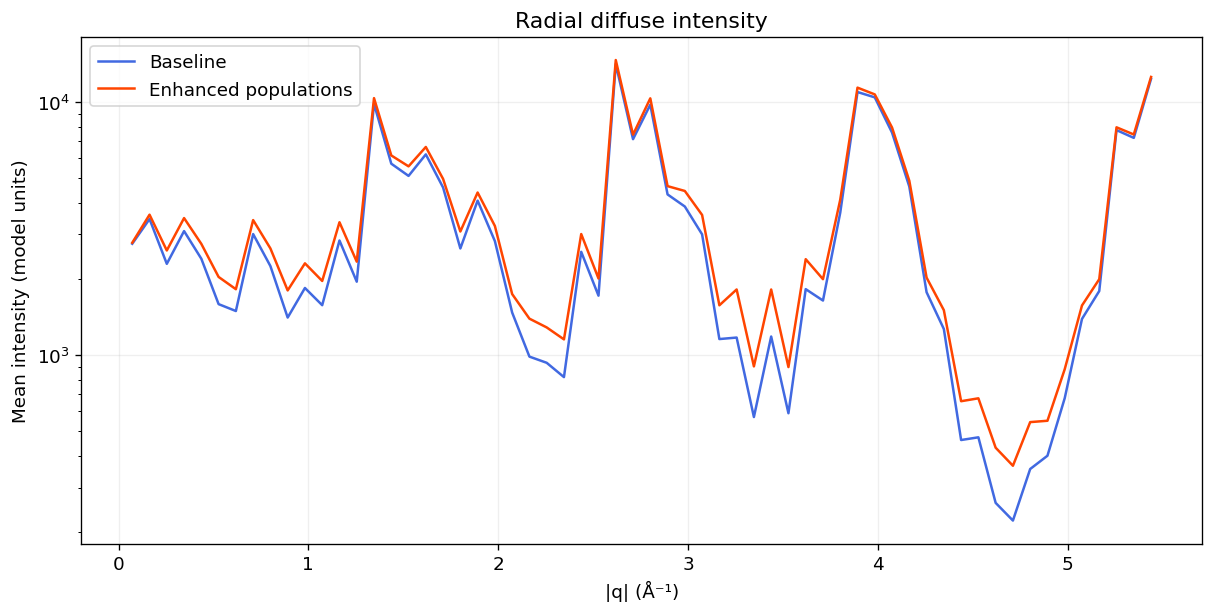

tmp/pytorch-notebook/results.npz
tmp/pytorch-notebook/slices.png
tmp/pytorch-notebook/pdos.dat
tmp/pytorch-notebook/pdos_populations.png
tmp/pytorch-notebook/example_population.dat
tmp/pytorch-notebook/population_histograms.dat
tmp/pytorch-notebook/population_comparison.npz
tmp/pytorch-notebook/population_comparison.png
tmp/pytorch-notebook/radial.dat
tmp/pytorch-notebook/radial.png


In [7]:
qnorm = np.linalg.norm(q, axis=1)
profile_before, q_edges, _ = binned_statistic(qnorm[common], I[common], statistic="mean", bins=60)
profile_after, _, _ = binned_statistic(qnorm[common], I_enhanced[common], statistic="mean", bins=q_edges)
q_centers = (q_edges[:-1] + q_edges[1:]) / 2
np.savetxt(OUT / "radial.dat", np.column_stack((q_centers, profile_before, profile_after)),
           header="q_inverse_angstrom baseline_mean enhanced_mean")
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.semilogy(q_centers, profile_before, label="Baseline", color="royalblue")
ax.semilogy(q_centers, profile_after, label="Enhanced populations", color="orangered")
ax.set(xlabel="|q| (Å⁻¹)", ylabel="Mean intensity (model units)", title="Radial diffuse intensity")
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(OUT / "radial.png", dpi=180)
plt.show()

with np.load(OUT / "results.npz") as saved:
    np.testing.assert_allclose(saved["intensity"], I, equal_nan=True)
    assert tuple(saved["map_shape"]) == model.map_shape
    assert saved["q_vectors"].shape == (I.size, 3)
np.testing.assert_allclose(model.Winv.cpu().numpy(), baseline_weights.cpu().numpy(), equal_nan=True)
assert np.isfinite(pdos).all() and np.isfinite(input_weight).all()
assert np.all(np.diff(f_grid) > 0) and np.all(input_weight >= 0)
for name in ("results.npz", "slices.png", "pdos.dat", "pdos_populations.png",
             "example_population.dat", "population_histograms.dat", "population_comparison.npz",
             "population_comparison.png", "radial.dat", "radial.png"):
    output = OUT / name
    assert output.is_file() and output.stat().st_size > 0, name
    print(output.relative_to(ROOT))